In [22]:
import pandas as pd
import numpy as np


In [23]:
df=pd.read_csv("data/RELIANCE.csv",parse_dates=["Date"],index_col="Date").sort_index()


df.head()

,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
Date,,,,,,,,,,,,,,
2000-01-03,RELIANCE,EQ,233.05,237.50,251.70,237.50,251.70,251.70,249.37,4456424,1.111319e+14,NaN,NaN,NaN
2000-01-04,RELIANCE,EQ,251.70,258.40,271.85,251.30,271.85,271.85,263.52,9487878,2.500222e+14,NaN,NaN,NaN
2000-01-05,RELIANCE,EQ,271.85,256.65,287.90,256.65,286.75,282.50,274.79,26833684,7.373697e+14,NaN,NaN,NaN
2000-01-06,RELIANCE,EQ,282.50,289.00,300.70,289.00,293.50,294.35,295.45,15682286,4.633254e+14,NaN,NaN,NaN
2000-01-07,RELIANCE,EQ,294.35,295.00,317.90,293.00,314.50,314.55,308.91,19870977,6.138388e+14,NaN,NaN,NaN


In [24]:
df["Daily_Return"]=df["Close"].pct_change()
df["Next_Day_Return"]=df["Daily_Return"].shift(-1)
df['Target_Direction']=np.where(df["Next_Day_Return"]>0,1,0)

print("total rows :",len(df))

total rows : 5306


#Phase 2: Engineering Stationary Alpha Features (Cell 2)
Never feed raw Close or raw Volume into a tree model—they drift over decades. Instead, we normalize them into ratios and oscillators that stay bounded and meaningful across any market regime:
RSI (14-day): Measures momentum from 0 to 100. Below 30 signals oversold conditions (like a crash bottom); above 70 signals overbought.
Price-to-SMA50 Ratio: Tells the model how stretched the stock is relative to its 50-day trend.
Volume Ratio: Compares today's volume to the 20-day average to detect institutional conviction.


In [25]:
# engineering stationary alpha features

# engineer 14 day RSI
delta=df["Close"].diff()
gain=delta.clip(lower=0).rolling(window=14).mean()
loss=-delta.clip(upper=0).rolling(window=14).mean()
rs=gain/loss

df["RSI_14"]=100-(100/(1 + rs))

# engineer trend ditance (close / 50 day SMA)
df["Price_SMA50_Ratio"]=df["Close"]/df["Close"].rolling(window=50).mean()

#engineer volume spike ratio (volume / 20 -day avg volume)
df["Volume_Ratio"]=df["Volume"]/df["Volume"].rolling(window=20).mean()

# keep volatility from yesterday
df["Volatility_20d"]=df["Daily_Return"].rolling(window=20).std()

#clean the NaN 
df.dropna(inplace=True)

features=["Daily_Return","RSI_14","Price_SMA50_Ratio","Volume_Ratio","Volatility_20d"]
print("engineered alpha features:-")
print(df[features].tail())

engineered alpha features:-
            Daily_Return     RSI_14  Price_SMA50_Ratio  Volume_Ratio  \
Date                                                                   
2021-04-23     -0.001075  30.648638           0.933643      0.685542   
2021-04-26      0.017591  34.438681           0.950194      1.196301   
2021-04-27      0.026215  49.322354           0.974792      1.136939   
2021-04-28      0.004350  52.227553           0.978811      0.987421   
2021-04-29      0.013393  53.533333           0.992229      1.012233   

            Volatility_20d  
Date                        
2021-04-23        0.013963  
2021-04-26        0.014339  
2021-04-27        0.015301  
2021-04-28        0.014063  
2021-04-29        0.014367  


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

train_df=df.loc[:"2019-12-31"]
test_df=df.loc["2020-01-01":].copy()

x_train,y_train=train_df[features],train_df["Target_Direction"]
x_test,y_test=test_df[features],test_df["Target_Direction"]



In [27]:
quant_pipeline=Pipeline(
    steps=[
        ("scaler",StandardScaler()),
        ("model",RandomForestClassifier(n_estimators=100,max_depth=5,random_state=42))
    ]
)
quant_pipeline.fit(x_train,y_train)


test_df["Signal"]=quant_pipeline.predict(x_test)
test_df["Strategy_Return"]=test_df["Signal"]*test_df["Next_Day_Return"]

test_df["Buy_Hold_Equity"]=(1+test_df["Next_Day_Return"]).cumprod()
test_df["Strategy_Equity"]=(1+test_df["Strategy_Return"]).cumprod()




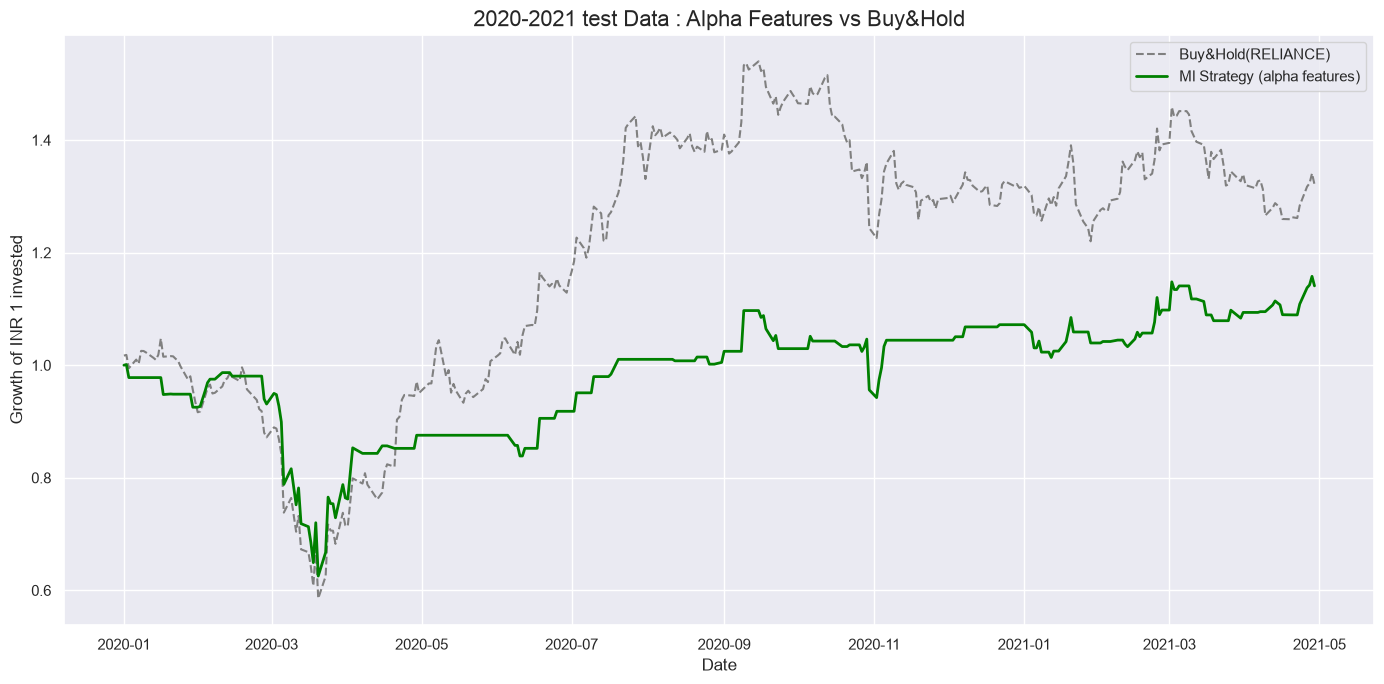

In [28]:
#plto

sns.set_theme(style="darkgrid")
plt.figure(figsize=(14,7))
sns.lineplot(data=test_df,x=test_df.index,y="Buy_Hold_Equity",label="Buy&Hold(RELIANCE)",color="grey",linestyle="--")
sns.lineplot(data=test_df,x=test_df.index,y="Strategy_Equity",label="Ml Strategy (alpha features)",color="green",linewidth=2)
plt.title("2020-2021 test Data : Alpha Features vs Buy&Hold",fontsize=16)
plt.xlabel("Date")
plt.ylabel("Growth of INR 1 invested")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
print(f"Final Buy & Hold Value: INR {test_df['Buy_Hold_Equity'].iloc[-1]:.2f}")
print(f"Final ML Strategy Value: INR {test_df['Strategy_Equity'].iloc[-1]:.2f}")

Final Buy & Hold Value: INR 1.32
Final ML Strategy Value: INR 1.14
